# 03 — Modeling

Step 3: preprocessing `Pipeline` + Logistic Regression, scored with 5-fold CV on the train set and compared with the baselines from `02_baseline.ipynb`.

Rules
- All preprocessing sits inside the `Pipeline`, so it is fitted on train folds only (no leakage).
- The test set is not touched until the final evaluation (step 7).
- Later steps add more models to this notebook.

Run `02_baseline.ipynb` first (it creates `reports/baseline_cv_results.csv`).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
sys.path.append(str(Path('..').resolve()))
from src.data import RANDOM_STATE, get_split
from src.evaluate import SCORERS, cv_scores, format_table, make_cv
from src.pipeline import build_pipeline, split_columns

np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)

REPORT_DIR = Path('../reports')
FIG_DIR = REPORT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## 1. Data

In [2]:
X_train, X_test, y_train, y_test = get_split()
num_cols, cat_cols = split_columns(X_train)

print('train:', X_train.shape, '| numeric:', len(num_cols), '| categorical:', len(cat_cols))
print('numeric:', num_cols)

train: (5634, 19) | numeric: 3 | categorical: 16
numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']


## 2. Pipeline

- Numeric: median imputer, then `StandardScaler`.
- Categorical (incl. `SeniorCitizen`): most-frequent imputer, then `OneHotEncoder(handle_unknown='ignore', drop='if_binary')`.
- Model: `LogisticRegression`.

In [3]:
pipe = build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train)
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output o

## 3. Logistic Regression (5-fold CV on train)

Two versions: default, and `class_weight='balanced'` to handle the 26.5% churn rate.

In [4]:
models = {
    'LogReg': build_pipeline(
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train),
    'LogReg (balanced)': build_pipeline(
        LogisticRegression(max_iter=1000, class_weight='balanced',
                           random_state=RANDOM_STATE), X_train),
}

cv = make_cv()
records = {name: cv_scores(m, X_train, y_train, cv=cv) for name, m in models.items()}
results = pd.DataFrame(records).T
results.index.name = 'model'
results.round(4).to_csv(REPORT_DIR / 'cv_results.csv')
display(format_table(results))
display((results['train_f1_mean'] - results['f1_mean']).round(3).rename('train F1 - CV F1'))

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
LogReg,0.802 +/- 0.012,0.653 +/- 0.027,0.544 +/- 0.041,0.593 +/- 0.030,0.846 +/- 0.013,0.662 +/- 0.019
LogReg (balanced),0.749 +/- 0.015,0.518 +/- 0.019,0.803 +/- 0.036,0.629 +/- 0.022,0.846 +/- 0.012,0.660 +/- 0.020


model
LogReg               0.010
LogReg (balanced)    0.004
Name: train F1 - CV F1, dtype: float64

**Result:** plain LogReg: F1 0.59, recall 0.54, precision 0.65, ROC-AUC 0.85, PR-AUC 0.66. Train F1 is only ~0.01 above CV F1, so no overfitting.


## 4. Comparison with baselines

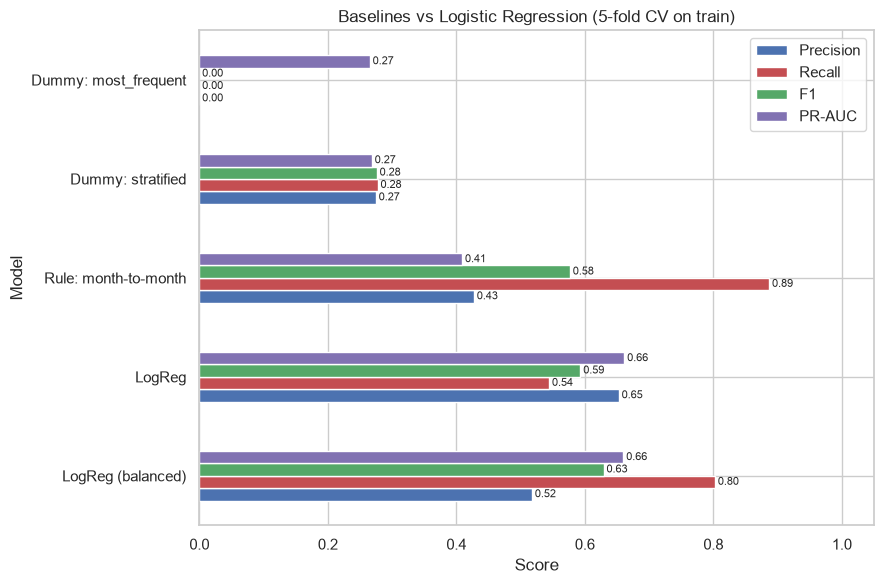

In [5]:
baselines = pd.read_csv(REPORT_DIR / 'baseline_cv_results.csv', index_col='model')
compare = pd.concat([baselines, results[baselines.columns]])
plot_df = compare[['precision_mean', 'recall_mean', 'f1_mean', 'pr_auc_mean']].copy()
plot_df.columns = ['Precision', 'Recall', 'F1', 'PR-AUC']
ax = plot_df.iloc[::-1].plot(kind='barh', figsize=(9, 6),color=['#4C72B0', '#C44E52', '#55A868', '#8172B2'])
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=8, padding=2)
ax.set_title('Baselines vs Logistic Regression (5-fold CV on train)')
ax.set_xlabel('Score')
ax.set_ylabel('Model')
ax.set_xlim(0, 1.05)
save_fig('11_model_comparison_logreg')
plt.show()

**Result:** both LogReg versions clearly beat the baselines on PR-AUC (0.66 vs 0.41) and ROC-AUC (0.85 vs 0.73). On F1, plain LogReg (0.59) is barely above the month-to-month rule (0.58); the balanced version (0.63) is clearly better.

## 5. Coefficients

Fitted on the train set only, for interpretation.

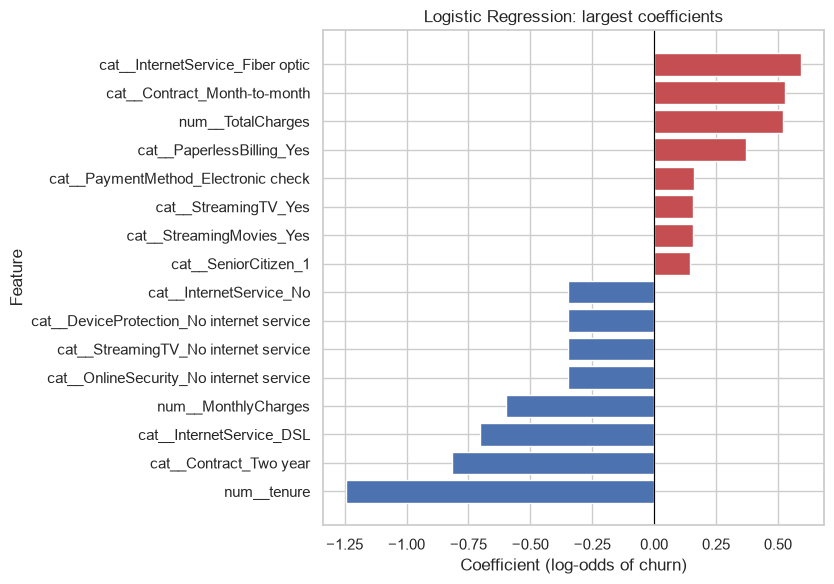

In [6]:
final = build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train).fit(X_train, y_train)
names = final.named_steps['pre'].get_feature_names_out()
coef = pd.Series(final.named_steps['model'].coef_[0], index=names).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(top.index, top.values, color=np.where(top.values < 0, '#4C72B0', '#C44E52'))
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Logistic Regression: largest coefficients')
ax.set_xlabel('Coefficient (log-odds of churn)')
ax.set_ylabel('Feature')
save_fig('12_logreg_coefficients')
plt.show()

**Result:** churn goes up with fiber optic, month-to-month contract, paperless billing and electronic check; it goes down with long tenure, a two-year contract and DSL.